# **K-Nearest Neighbors (KNN) Classification on D&D Monsters**

In this notebook, we will classify Dungeons & Dragons monsters with the k-nearest neighbors (KNN) algorithm and examine why KNN requires feature scaling. Using each monster's ability scores and other game statistics, we predict whether the monster is **Unaligned**, the alignment that D&D assigns to creatures that cannot make moral choices, such as animals, golems, and oozes. We train KNN on the original features and examine how the number of neighbors, k, affects its accuracy. We then scale the features and compare the two versions of the model across different values of k.
____
We'll cover:
1. Loading and inspecting the dataset.
2. Preprocessing: Creating the target variable and selecting features.
3. Splitting the data into training and testing sets.
4. Training a KNN model.
5. Evaluating the KNN model.
6. Exploring the effect of different values of k.
7. Scaling the features.
8. Evaluating KNN with scaled features.
9. Comparing unscaled and scaled features across values of k.

## **Step 1: Load and Inspect the Data**

We use the D&D Monsters dataset from TidyTuesday. It contains the game statistics for 330 monsters, including their size, type, alignment, ability scores, and hit points.

In [1]:
# Import necessary libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the D&D Monsters dataset from TidyTuesday
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-05-27/monsters.csv"
df = pd.read_csv(url)

# Display the first five rows of the dataset
print("Shape:", df.shape)
print("\nFirst five rows:")
df.head()

Shape: (330, 33)

First five rows:


,name,category,cr,size,type,descriptive_tags,alignment,ac,initiative,hp,...,wis_save,cha_save,skills,resistances,vulnerabilities,immunities,gear,senses,languages,full_text
0,Aboleth,Aboleth,10.00,Large,Aberration,NaN,Lawful Evil,17,7,150 (20d10 + 40),...,6,4,"History +12, Perception +10",NaN,NaN,NaN,NaN,Darkvision 120 ft.; Passive Perception 20,Deep Speech; telepathy 120 ft.,"Aboleth\nLarge Aberration, Lawful Evil\nAC 17\..."
1,Air Elemental,Air Elemental,5.00,Large,Elemental,NaN,Neutral,15,5,90 (12d10 + 24),...,0,-2,NaN,"Bludgeoning, Lightning, Piercing, Slashing",NaN,"Poison, Thunder; Exhaustion, Grappled, Paralyz...",NaN,Darkvision 60 ft.; Passive Perception 10,Primordial (Auran),"Air Elemental\nLarge Elemental, Neutral\nAC 15..."
2,Animated Armor,Animated Objects,1.00,Medium,Construct,NaN,Unaligned,18,2,33 (6d8 + 6),...,-4,-5,NaN,NaN,NaN,"Poison, Psychic; Charmed, Deafened, Exhaustion...",NaN,Blindsight 60 ft.; Passive Perception 6,NaN,"Animated Armor\nMedium Construct, Unaligned\nA..."
3,Animated Flying Sword,Animated Objects,0.25,Small,Construct,NaN,Unaligned,17,4,14 (4d6),...,-3,-5,NaN,NaN,NaN,"Poison, Psychic; Charmed, Deafened, Exhaustion...",NaN,Blindsight 60 ft.; Passive Perception 7,NaN,"Animated Flying Sword\nSmall Construct, Unalig..."
4,Animated Rug of Smothering,Animated Objects,2.00,Large,Construct,NaN,Unaligned,12,4,27 (5d10),...,-4,-5,NaN,NaN,NaN,"Poison, Psychic; Charmed, Deafened, Exhaustion...",NaN,Blindsight 60 ft.; Passive Perception 6,NaN,"Animated Rug of Smothering\nLarge Construct, U..."


In [3]:
# Check available columns
print("Columns:")
print(df.columns.tolist())
print("\nAlignment distribution:")
print(df["alignment"].value_counts())

Columns:
['name', 'category', 'cr', 'size', 'type', 'descriptive_tags', 'alignment', 'ac', 'initiative', 'hp', 'hp_number', 'speed', 'speed_base_number', 'str', 'dex', 'con', 'int', 'wis', 'cha', 'str_save', 'dex_save', 'con_save', 'int_save', 'wis_save', 'cha_save', 'skills', 'resistances', 'vulnerabilities', 'immunities', 'gear', 'senses', 'languages', 'full_text']

Alignment distribution:
alignment
Unaligned          125
Neutral             50
Chaotic Evil        45
Lawful Evil         35
Neutral Evil        28
Lawful Good         20
Chaotic Good        11
Chaotic Neutral      7
Neutral Good         6
Lawful Neutral       3
Name: count, dtype: int64


### **Step 2: Data Preprocessing**

Our next step is to prepare the data for modeling:

- **Target Variable:** `is_unaligned` equals 1 if a monster's alignment is "Unaligned" and 0 otherwise. Most Unaligned monsters are beasts, such as apes and badgers, but the group also includes monsters such as the Owlbear and the Gelatinous Cube.
- **Features:** The six ability scores (`str`, `dex`, `con`, `int`, `wis`, `cha`), hit points (`hp_number`), challenge rating (`cr`), base speed (`speed_base_number`), and initiative bonus (`initiative`).
- **Missing Values:** We drop any rows with missing values in these columns.

*Note: The features are measured on very different scales. Ability scores range from 1 to 30, while hit points range from 1 to 697. We return to this difference in Step 7.*

In [4]:
# Create the binary target: 1 if the monster is Unaligned, 0 otherwise
df["is_unaligned"] = (df["alignment"] == "Unaligned").astype(int)

print("Binary target distribution:")
print(df["is_unaligned"].value_counts())

# Check which types of monsters are Unaligned
print("\nMonster types among Unaligned monsters:")
print(df.loc[df["is_unaligned"] == 1, "type"].value_counts())

Binary target distribution:
is_unaligned
0    205
1    125
Name: count, dtype: int64

Monster types among Unaligned monsters:
type
Beast                   84
Monstrosity             17
Construct                8
Swarm of Tiny Beasts     6
Ooze                     4
Plant                    3
Aberration               2
Dragon                   1
Name: count, dtype: int64


In [5]:
# Select numeric stat features
features = ["str", "dex", "con", "int", "wis", "cha", "hp_number", "cr", "speed_base_number", "initiative"]

# Drop rows with NaN in features or target
df_clean = df[features + ["is_unaligned"]].dropna()
print(f"Clean dataset shape: {df_clean.shape}")

X = df_clean[features]
y = df_clean["is_unaligned"]

# Compare the feature ranges
print("\nFeature ranges:")
print(X.describe().loc[["min", "max"]])

Clean dataset shape: (330, 11)

Feature ranges:
      str   dex   con   int   wis   cha  hp_number    cr  speed_base_number  \
min   1.0   1.0   8.0   1.0   3.0   1.0        1.0   0.0                5.0   
max  30.0  28.0  30.0  25.0  25.0  30.0      697.0  30.0               60.0   

     initiative  
min        -5.0  
max        20.0  


In [11]:
X.describe()

,str,dex,con,int,wis,cha,hp_number,cr,speed_base_number,initiative
count,330.000000,330.000000,330.000000,330.000000,330.000000,330.000000,330.000000,330.000000,330.000000,330.000000
mean,15.384848,12.833333,15.178788,7.863636,11.815152,9.918182,86.669697,4.551136,30.878788,3.148485
std,6.520047,3.261563,4.404492,5.675860,2.966748,5.969220,102.140570,5.797444,12.339566,3.944803
min,1.000000,1.000000,8.000000,1.000000,3.000000,1.000000,1.000000,0.000000,5.000000,-5.000000
25%,11.000000,10.000000,12.000000,2.000000,10.000000,5.000000,18.250000,0.500000,30.000000,1.000000
50%,16.000000,13.000000,14.500000,7.000000,12.000000,8.000000,52.000000,2.000000,30.000000,2.000000
75%,19.000000,15.000000,17.000000,12.000000,13.000000,14.000000,119.000000,6.000000,40.000000,4.000000
max,30.000000,28.000000,30.000000,25.000000,25.000000,30.000000,697.000000,30.000000,60.000000,20.000000


### **Step 3: Splitting the Data**

We split the dataset into training and testing sets. The training set is used to fit the KNN model, while the testing set is used to evaluate its performance.

*Note: We set `random_state=42` so that the split is reproducible.*

In [6]:
from sklearn.model_selection import train_test_split

# Split the dataset: 80% for training and 20% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42)

### **Step 4: Train the KNN Model**

KNN classifies a new monster by comparing it with the monsters in the training set:

- **Distance:** KNN calculates the distance between the new monster and every monster in the training set, using all of the features.
- **Neighbors:** It identifies the k training monsters that are closest to the new monster.
- **Vote:** It assigns the class held by the majority of those k neighbors.

Here, we train a KNN classifier with k = 5 on the original, unscaled features.

*Note: KNN does not learn any parameters during training. Calling `fit` stores the training data, and the distance calculations take place when the model makes predictions.*

In [8]:
# Import KNeighborsClassifier
from sklearn.neighbors import KNeighborsClassifier
# Initialize the KNN classifier with k=5 neighbors (default is 5), default metric is essentially euclidean 
knn = KNeighborsClassifier(n_neighbors = 5)

# Train the model using the training data
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


### **Step 5: Evaluate the Model**

We evaluate the model on the testing set with three measures:

- **Accuracy:** The proportion of test monsters that the model classifies correctly.
- **Confusion Matrix:** The counts of correct and incorrect predictions for each class.
- **Classification Report:** The precision, recall, and F1 score for each class.

Accuracy without scaling (k=5): 0.74


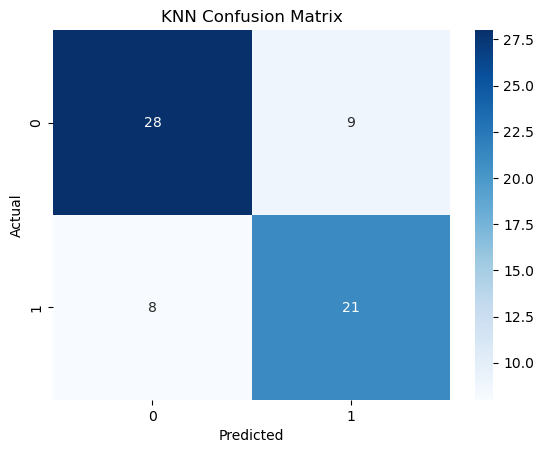


Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.76      0.77        37
           1       0.70      0.72      0.71        29

    accuracy                           0.74        66
   macro avg       0.74      0.74      0.74        66
weighted avg       0.74      0.74      0.74        66



In [9]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Predict the labels for the test dataset
y_pred = knn.predict(X_test)

# Calculate and print the accuracy of the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy without scaling (k=5): {accuracy:.2f}")

# Generate the confusion matrix and display it using a heatmap
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('KNN Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Print the classification report with detailed metrics
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

### **Step 6: Exploring the Effect of Different Values of k**

The number of neighbors, k, affects how KNN makes predictions:

- **Small k:** Each prediction depends on a few nearby monsters, so the model is sensitive to noise in the training data. This is a form of overfitting.
- **Large k:** Each prediction averages over many monsters, so the model may miss local patterns. This is a form of underfitting.

Here, we train KNN models on the unscaled features with odd values of k from 1 to 19 and plot the test accuracy of each model.

*Note: We use odd values of k so that a vote between two classes cannot end in a tie. Because this plot uses the testing set, it shows how k affects performance but should not be used to choose a final value of k. To choose k, we would use cross-validation on the training data, as GridSearchCV did in Week 9.*

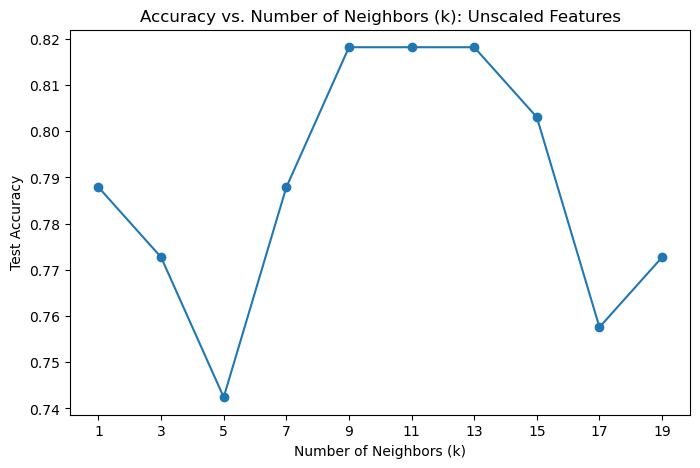

In [10]:
# Define a range of k values to explore (odd numbers only)
k_values = range(1, 20, 2)
accuracies = []

# Loop through different values of k
for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors = k)
    knn_temp.fit(X_train, y_train)
    y_temp_pred = knn_temp.predict(X_test)
    accuracies.append(accuracy_score(y_test, y_temp_pred))

# Plot accuracy vs. number of neighbors (k) for the unscaled data
plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, marker='o')
plt.title('Accuracy vs. Number of Neighbors (k): Unscaled Features')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Test Accuracy')
plt.xticks(k_values)
plt.show()

### **Step 7: Scaling the Features**

KNN measures how close two monsters are with **Euclidean distance**, which adds up the squared differences between the monsters across all features. A feature with a large range therefore contributes more to the distance than a feature with a small range. In this dataset, hit points range from 1 to 697, while intelligence ranges from 1 to 25, so a difference of 50 hit points counts for more than the largest possible difference in intelligence. Without scaling, a monster's nearest neighbors are mostly the monsters with similar hit points.

We use standardization to put every feature on the same scale:

- **Standardization:** Rescales each feature to have a mean of 0 and a standard deviation of 1.
- **`fit_transform` on the Training Set:** Computes each feature's mean and standard deviation from the training data and then rescales the training data.
- **`transform` on the Testing Set:** Rescales the testing data with the mean and standard deviation from the training data.

*Note: We fit the scaler on the training data only. Fitting it on the full dataset would allow information from the testing set to leak into the model.*

In [12]:
from sklearn.preprocessing import StandardScaler

# Initialize the StandardScaler
scaler = StandardScaler()

# Fit the scaler on the training data and transform both training and test data
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Optional: Convert the scaled training data back to a DataFrame for inspection
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=features, index=X_train.index)
print("Scaled training features preview:")
print(X_train_scaled_df.head())

Scaled training features preview:
          str       dex       con       int       wis       cha  hp_number  \
75   0.535651 -1.267534  0.588504 -0.363235 -0.654350 -0.841733   0.368397   
184  1.136126 -0.954797  1.256263  1.016536 -0.317608  1.467878   0.766314   
17   1.136126  0.921628  0.588504 -0.190764  0.692616  0.313072   0.766314   
24  -0.515180  1.234365 -0.747013  0.326650  0.355875  0.148100  -0.650659   
180 -1.415893  0.296153 -0.524427 -0.363235 -0.654350 -0.346817  -0.602133   

           cr  speed_base_number  initiative  
75   0.049971          -0.123172   -1.085675  
184  0.726499           0.732547    0.150814  
17   1.064763           1.588266   -0.096484  
24  -0.753406           0.732547   -0.096484  
180 -0.711123           0.732547   -0.343781  


### **Step 8: Evaluate the Model with Scaled Features**

We train a new KNN model on the scaled features with the same setting (k = 5) and evaluate it with the same three measures as in Step 5. Because only the features have changed, any difference in performance is due to scaling.

Accuracy with scaling (k=5): 0.88


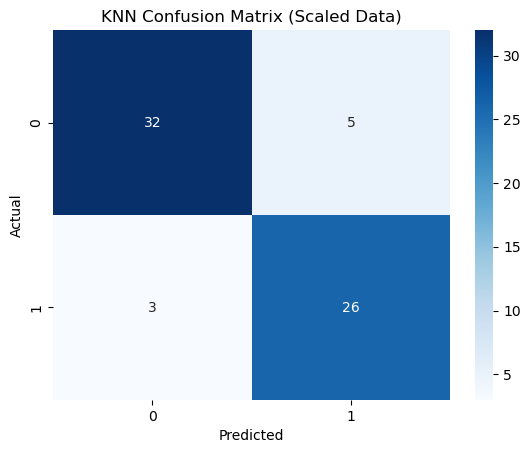


Classification Report (Scaled Data):
              precision    recall  f1-score   support

           0       0.91      0.86      0.89        37
           1       0.84      0.90      0.87        29

    accuracy                           0.88        66
   macro avg       0.88      0.88      0.88        66
weighted avg       0.88      0.88      0.88        66



In [13]:
# Initialize and train the KNN classifier with k=5 neighbors on the scaled data
knn_scaled = KNeighborsClassifier(n_neighbors=5)
knn_scaled.fit(X_train_scaled, y_train)

# Predict the labels for the scaled test data
y_pred_scaled = knn_scaled.predict(X_test_scaled)

# Calculate and print the accuracy for the scaled data
accuracy_scaled = accuracy_score(y_test, y_pred_scaled)
print(f"Accuracy with scaling (k=5): {accuracy_scaled:.2f}")

# Generate and display the confusion matrix for the scaled data using a heatmap
cm_scaled = confusion_matrix(y_test, y_pred_scaled)
sns.heatmap(cm_scaled, annot=True, fmt='d', cmap='Blues')
plt.title('KNN Confusion Matrix (Scaled Data)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Print the classification report for the scaled data
print("\nClassification Report (Scaled Data):")
print(classification_report(y_test, y_pred_scaled))

### **Step 9: Comparing Unscaled and Scaled Features Across Values of k**

We repeat the loop from Step 6 on the scaled features and plot both sets of test accuracies on the same chart. This shows whether the improvement from scaling in Step 8 holds for every value of k or only for k = 5.

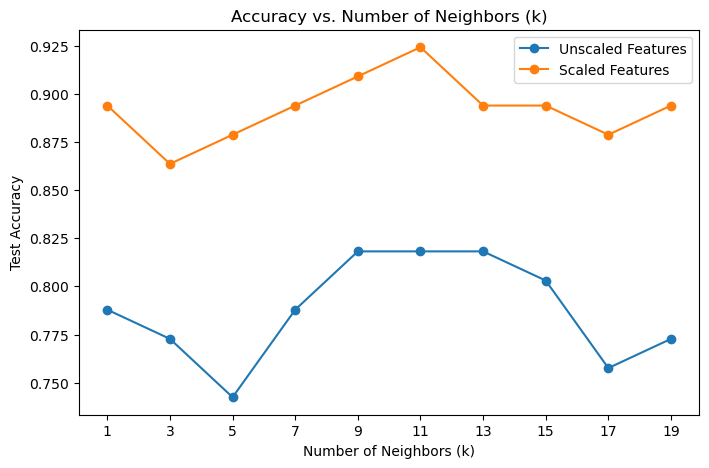

In [14]:
# Loop through the same k values, this time on the scaled features
accuracies_scaled = []
for k in k_values:
    knn_temp_scaled = KNeighborsClassifier(n_neighbors=k)
    knn_temp_scaled.fit(X_train_scaled, y_train)
    y_temp_pred = knn_temp_scaled.predict(X_test_scaled)
    accuracies_scaled.append(accuracy_score(y_test, y_temp_pred))

# Plot both curves (the unscaled accuracies come from Step 6)
plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, marker='o', label='Unscaled Features')
plt.plot(k_values, accuracies_scaled, marker='o', label='Scaled Features')
plt.title('Accuracy vs. Number of Neighbors (k)')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Test Accuracy')
plt.xticks(k_values)
plt.legend()
plt.show()